# Conformal calibration for new people

Checking whether a 90% target still holds up for people the model has not seen.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

results = Path("results")
wisdm_results = Path("wisdm_results")

names = {
    "window_aps": "Window APS",
    "window_raps": "Window RAPS",
    "participant_aps": "Participant APS",
    "participant_raps": "Participant RAPS",
}

def summary(path):
    cols = [
        "coverage_equal_subject",
        "coverage_p10_subject",
        "fraction_people_below_target",
        "mean_set_size_equal_subject",
        "review_rate_equal_subject",
    ]
    table = pd.read_csv(path)
    table = table[table.alpha == 0.1].groupby(["family", "method"], as_index=False)[cols].mean()
    table["method"] = table["method"].map(names)
    table[[cols[0], cols[1], cols[2], cols[4]]] *= 100
    table.columns = ["model", "method", "mean coverage (%)", "p10 coverage (%)", "below 90% (%)", "set size", "review (%)"]
    return table.round(2)

## UCI HAR

,model,method,mean coverage (%),p10 coverage (%),below 90% (%),set size,review (%)
0,Forest,Participant APS,98.77,96.89,0.00,2.26,81.02
1,Forest,Participant RAPS,97.70,95.31,0.00,1.71,68.10
2,Forest,Window APS,96.90,93.35,0.00,1.60,55.47
3,Forest,Window RAPS,95.92,91.56,5.56,1.47,44.95
4,Logistic,Participant APS,99.56,98.90,0.00,3.00,79.68
5,Logistic,Participant RAPS,97.60,92.59,4.44,1.45,44.18
6,Logistic,Window APS,98.75,95.88,1.11,1.93,57.77
7,Logistic,Window RAPS,93.85,85.83,21.11,1.07,6.71


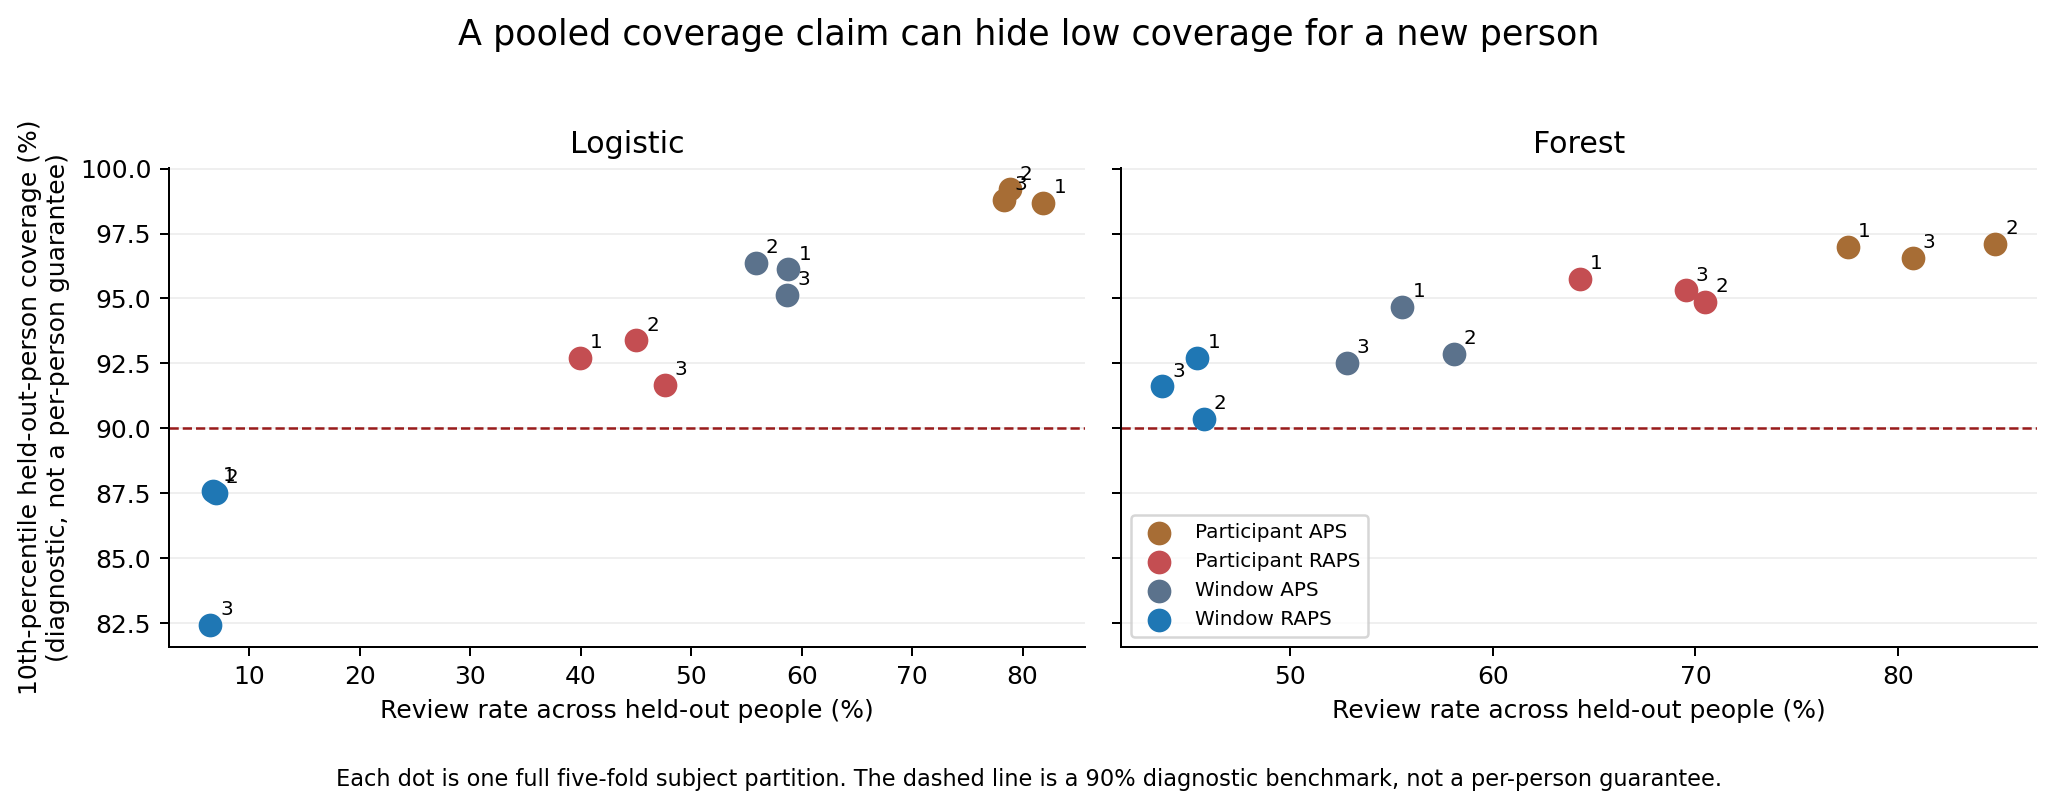

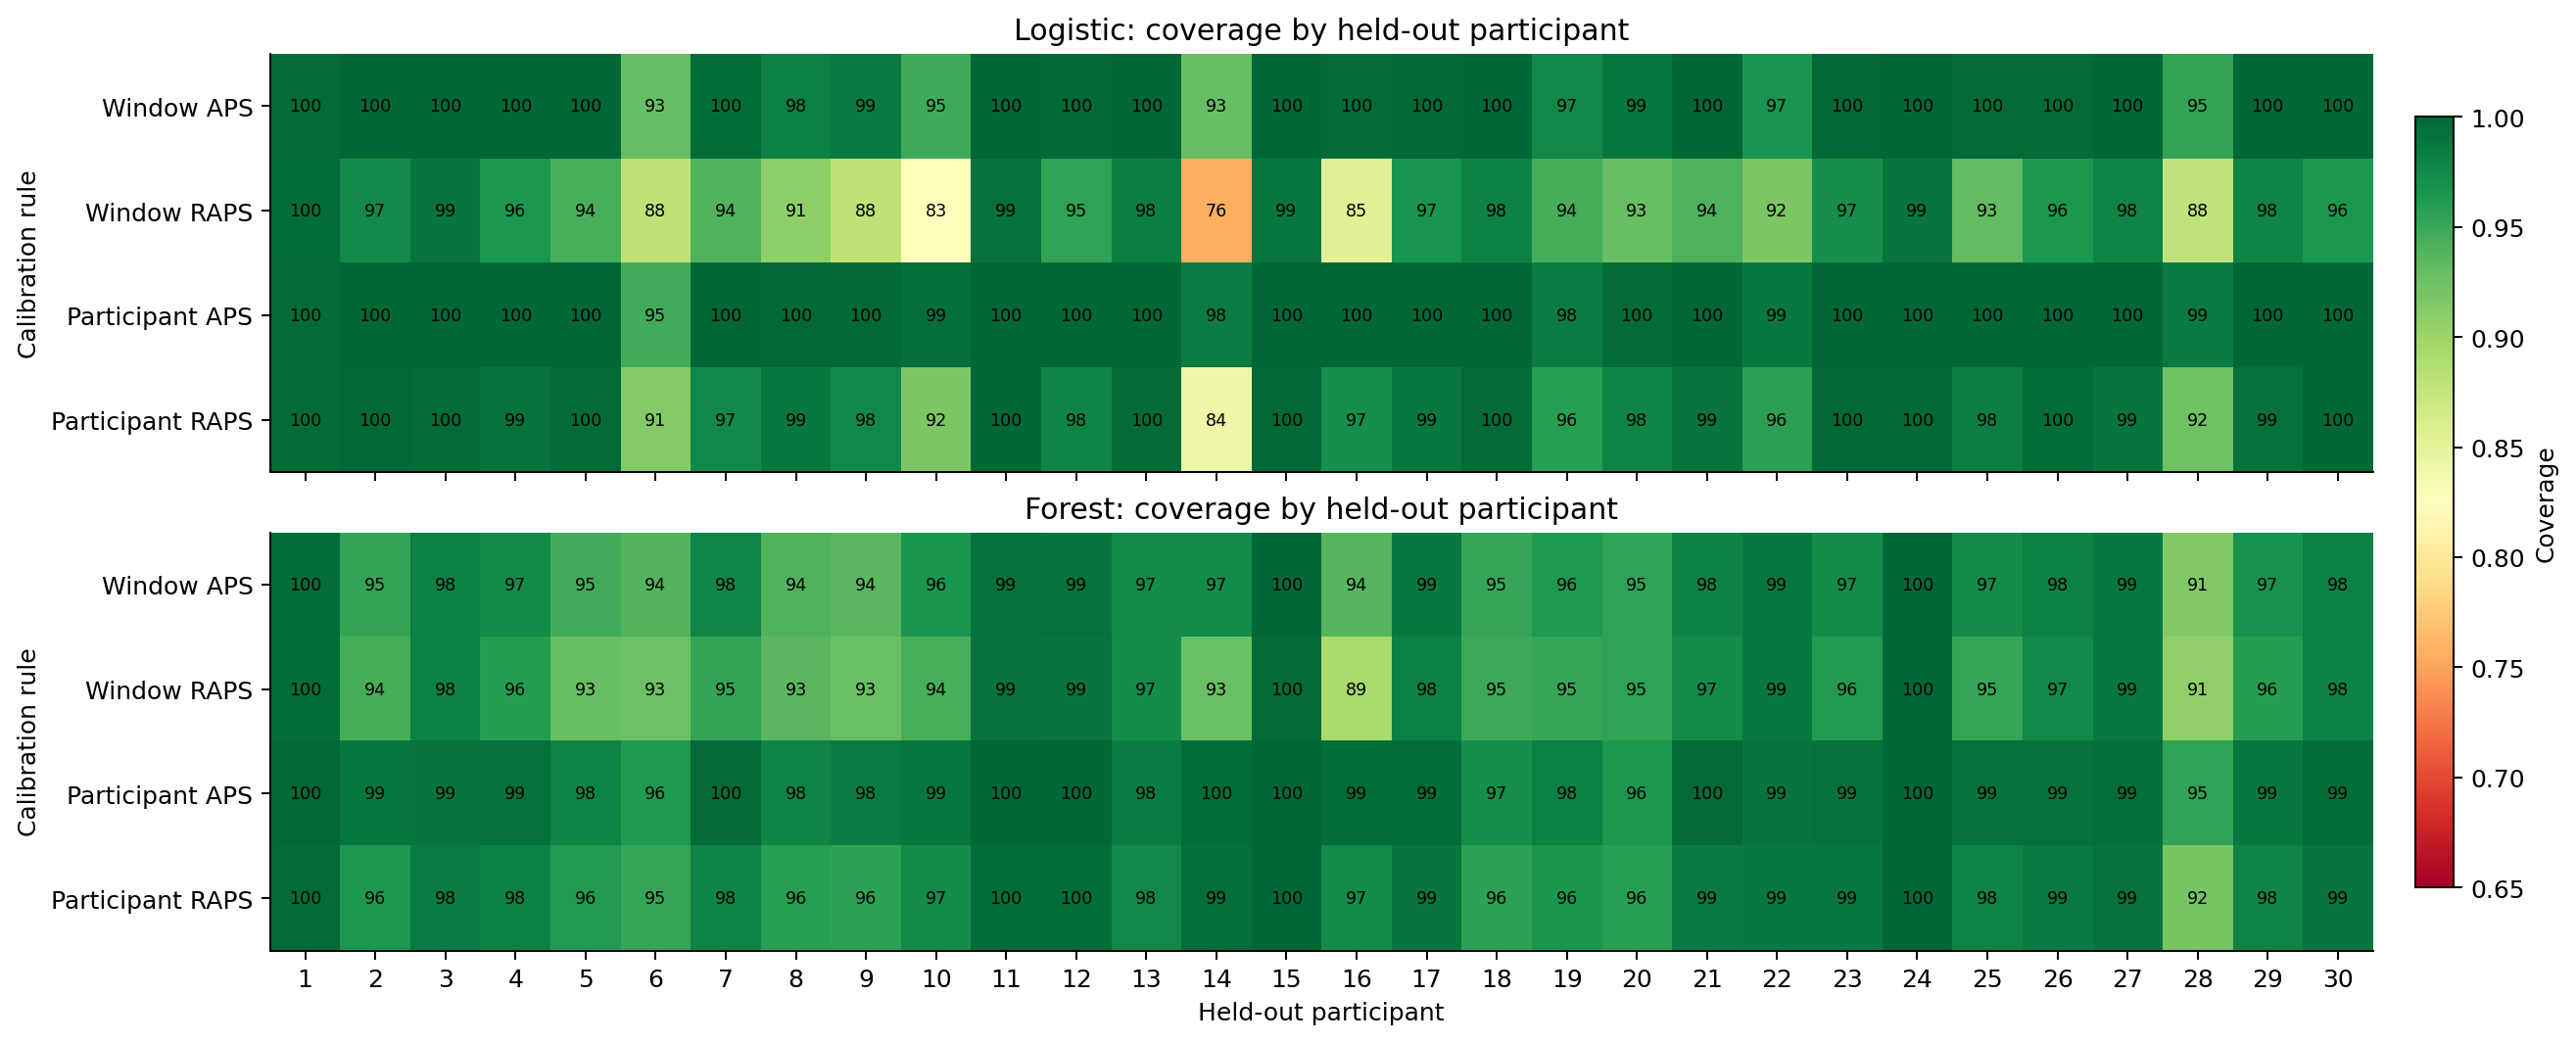

In [2]:
display(summary(results / "repeat_summary.csv"))
display(Image(filename=str(results / "coverage_vs_review.png")))
display(Image(filename=str(results / "subject_coverage.png")))

## Shift check

Quick check: are people farther from the training/calibration data also the ones with worse coverage?

,model,method,rho
0,Forest,Participant APS,-0.224
1,Forest,Participant RAPS,-0.271
2,Forest,Window APS,-0.408
3,Forest,Window RAPS,-0.496
4,Logistic,Participant APS,-0.470
5,Logistic,Participant RAPS,-0.263
6,Logistic,Window APS,-0.387
7,Logistic,Window RAPS,-0.345


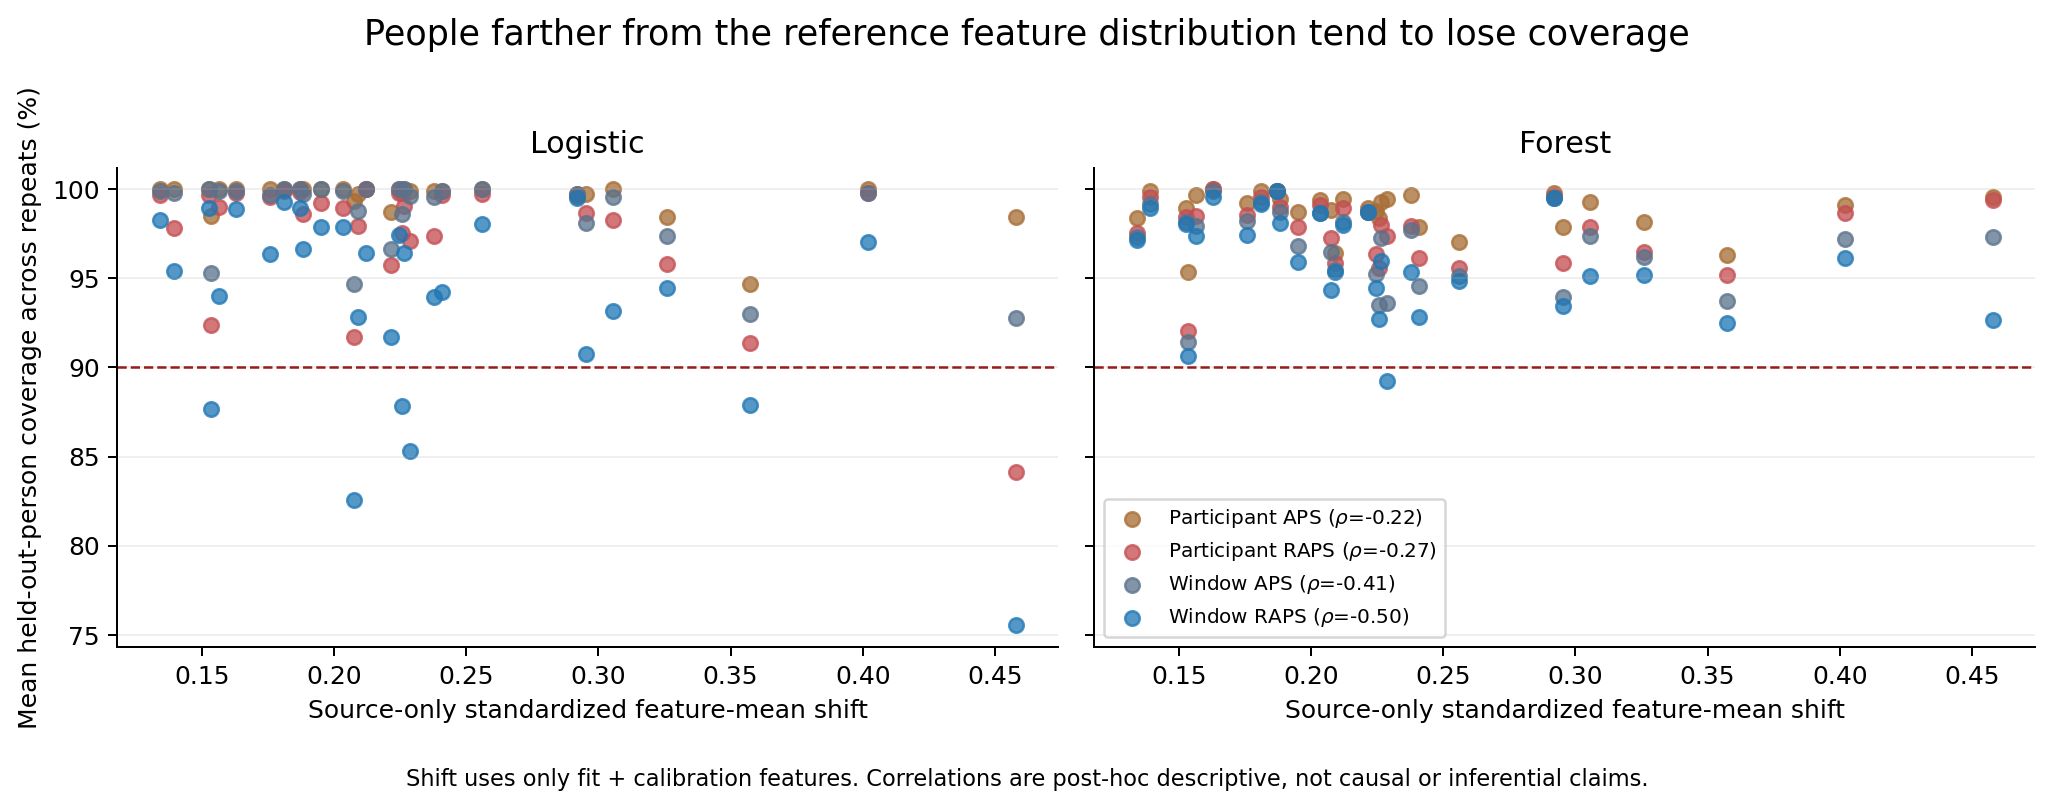

In [3]:
shift = pd.read_csv(results / "shift_diagnostic.csv")
shift = shift.groupby(["family", "method_label"], as_index=False)["spearman_rho"].first()
shift.columns = ["model", "method", "rho"]

display(shift.round(3))
display(Image(filename=str(results / "shift_vs_coverage.png")))

## Toy example

If easier people contribute more windows, they have more influence on a pooled cutoff. I made a small toy version to see what that does.

,case,rule,mean coverage (%),hard coverage (%),p10 coverage (%),below 90% (%)
0,equal windows,pooled windows,90.03,60.13,59.46,25.00
1,equal windows,participant balanced,94.50,78.02,77.48,25.00
2,size-biased windows,pooled windows,69.92,0.73,0.53,28.44
3,size-biased windows,participant balanced,94.38,77.53,77.00,24.99


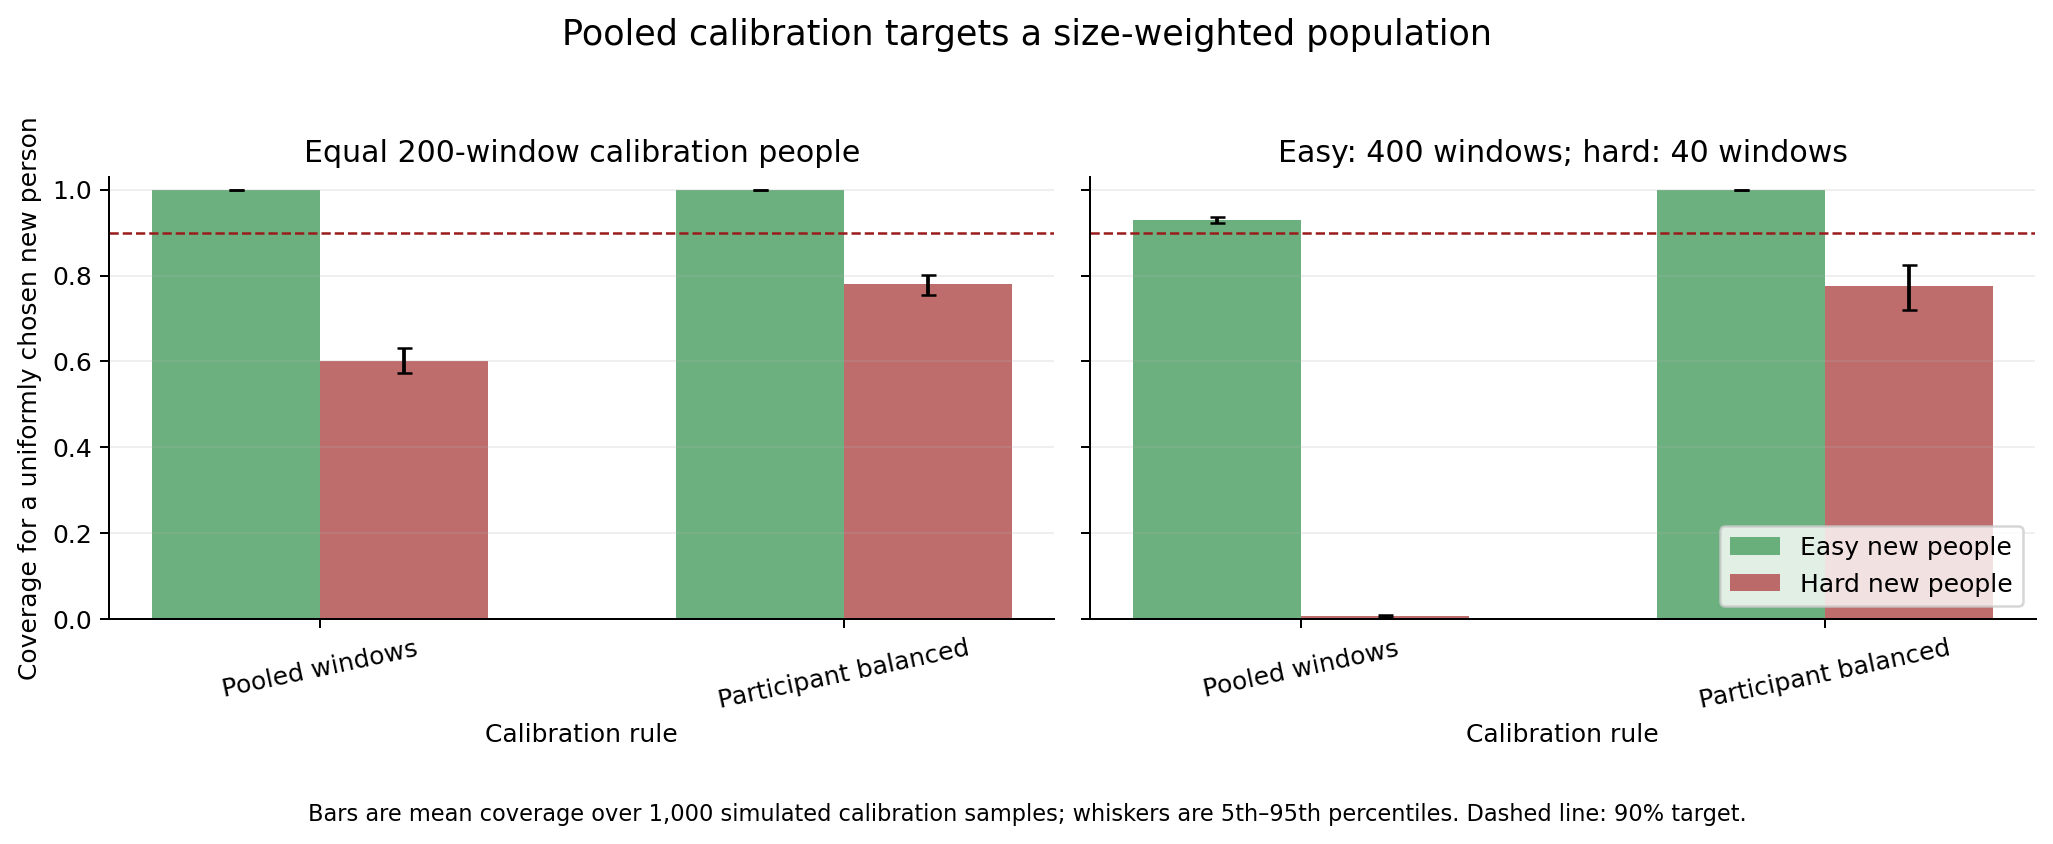

In [4]:
sim = pd.read_csv(results / "simulation_summary.csv")
sim = sim[[
    "regime",
    "method",
    "mean_equal_person_coverage",
    "mean_hard_person_coverage",
    "mean_p10_person_coverage",
    "mean_fraction_people_below_target",
]].copy()
sim.iloc[:, 2:] *= 100
sim["regime"] = sim["regime"].replace({
    "equal_windows": "equal windows",
    "size_biased_windows": "size-biased windows",
})
sim["method"] = sim["method"].replace({
    "pooled_window": "pooled windows",
    "participant_balanced": "participant balanced",
})
sim.columns = ["case", "rule", "mean coverage (%)", "hard coverage (%)", "p10 coverage (%)", "below 90% (%)"]

display(sim.round(2))
display(Image(filename=str(results / "simulation_mechanism.png")))

## WISDM

I ran the same thing on a second activity dataset. I found six duplicate copies of subject 1610's file and dropped them before splitting. That leaves 44 file-level subjects, 18 activities, and 20,650 windows.

,model,method,mean coverage (%),p10 coverage (%),below 90% (%),set size,review (%)
0,Forest,Participant APS,95.25,90.24,9.09,12.25,99.83
1,Forest,Participant RAPS,94.45,87.45,18.18,11.05,99.96
2,Forest,Window APS,88.73,79.24,46.21,9.51,99.30
3,Forest,Window RAPS,88.72,79.41,48.48,9.36,99.96
4,Logistic,Participant APS,95.71,87.81,14.39,12.20,98.95
5,Logistic,Participant RAPS,95.11,87.81,15.91,12.13,100.00
6,Logistic,Window APS,91.82,82.00,31.06,10.56,98.18
7,Logistic,Window RAPS,90.76,80.56,35.61,10.31,100.00


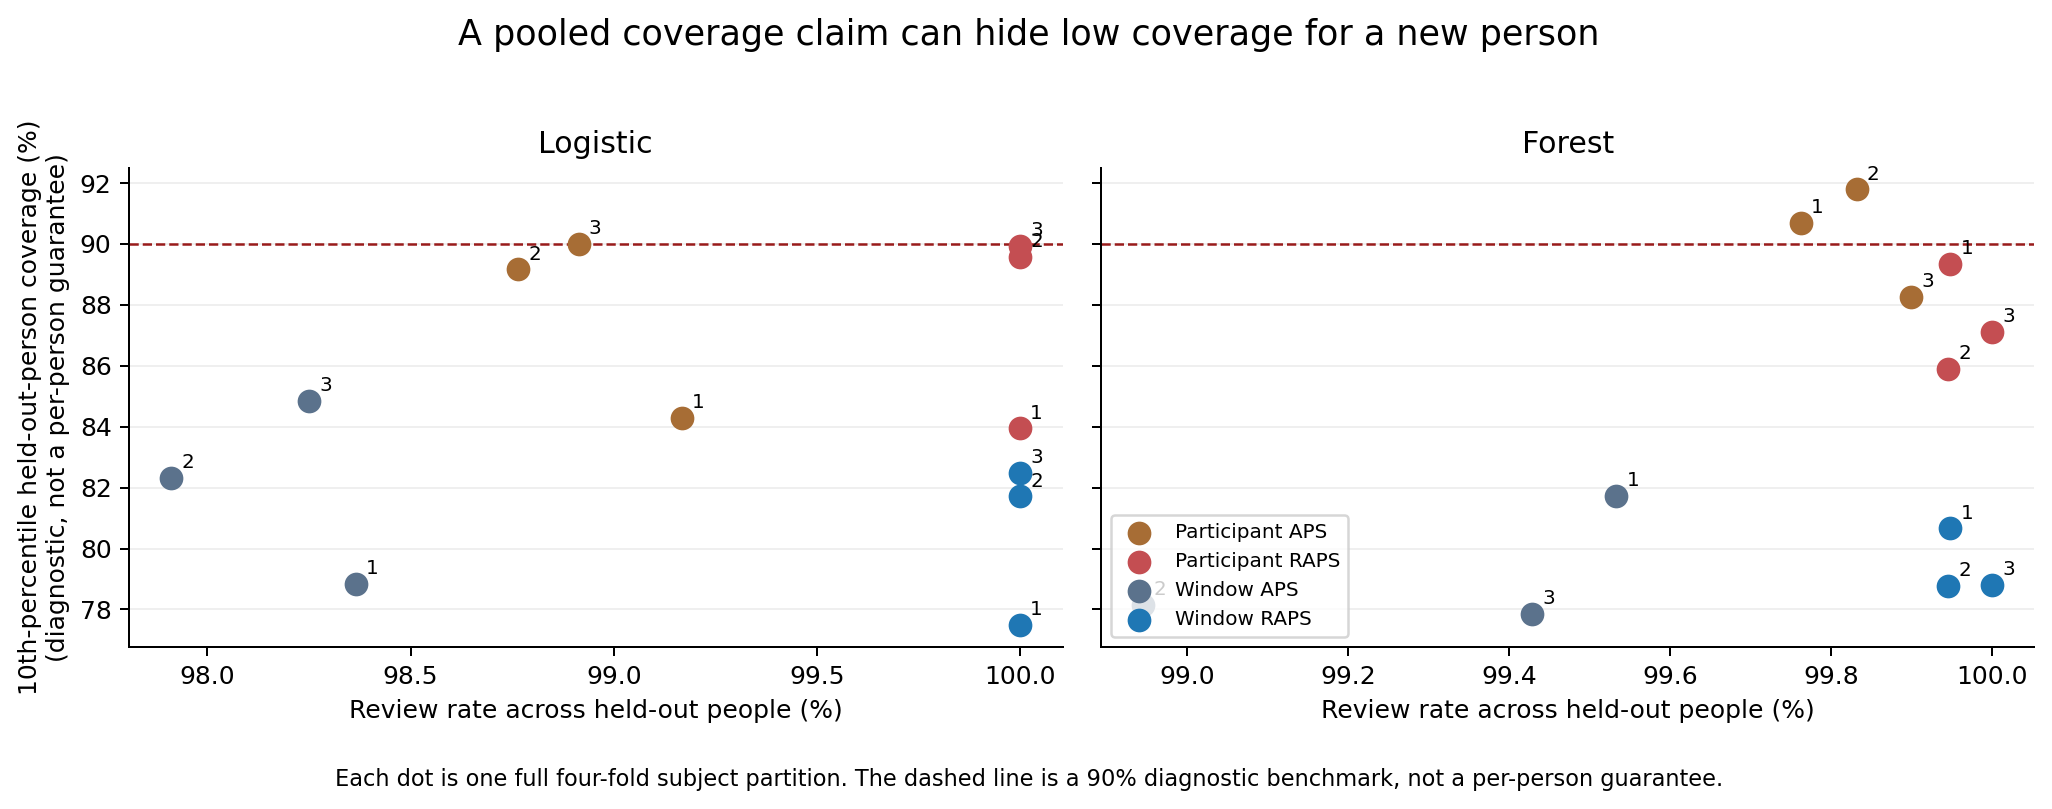

In [5]:
display(summary(wisdm_results / "repeat_summary.csv"))
display(Image(filename=str(wisdm_results / "coverage_vs_review.png")))

## Notes

- UCI HAR only has 30 people, and its windows overlap.
- The shift plot is correlation only.
- The participant-balanced version assumes the new test people are drawn like the calibration people.
- WISDM has 18 activities, so nearly everything ends up in review.

Sources: [APS](https://proceedings.neurips.cc/paper_files/paper/2020/file/244edd7e85dc81602b7615cd705545f5-Paper.pdf), [hierarchical conformal inference](https://arxiv.org/abs/2306.06342), [UCI HAR](https://doi.org/10.24432/C54S4K), and [WISDM](https://doi.org/10.24432/C5HK59).

## Rerun

Set `rerun` to `True` to download the public data and rerun everything. WISDM takes a few minutes.

In [6]:
rerun = False

if rerun:
    from run_experiment import run_experiment
    from shift_diagnostic import run as run_shift_diagnostic
    from hierarchical_simulation import main as run_simulation
    from wisdm_replication import run_experiment as run_wisdm

    run_experiment(Path("data"), results)
    run_shift_diagnostic(Path("data/UCI HAR Dataset"), results)
    run_simulation(results, repetitions=1000)
    run_wisdm(Path("wisdm_data"), wisdm_results)